# Lab 4: Unsupervised learning I (clustering and PCA)

Find structure without an answer key: choose K from evidence, compare K-means with DBSCAN, and
judge PCA by reconstruction and by what it does to a downstream classifier.

This notebook follows the Lab 4 handout: Parts A to C, then the *Try it yourself* task, the
verification checklist and the *Check your understanding* questions. The questions from
Chapters 15 and 16, which came with this lab, are answered at the end. The code saves every
chart and table to `results/lab04/` and the PCA model to `models/`.

In [1]:
import json
import zipfile
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Notebooks live in all_experiments/, so the course folder is one level up.
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)
RESULTS = PROJECT_ROOT / "results" / "lab04"
RESULTS.mkdir(parents=True, exist_ok=True)
summary = {}  # headline numbers, saved to results/lab04/summary.json at the end

# Dark charts to match the README. All six cluster colours pass a colour-blindness check on this
# background, and each cluster also gets its own marker shape.
CYAN, ORANGE, INK, MUTED, GRID = "#2f9fd6", "#d86f2e", "#e6edf3", "#8b949e", "#30363d"
CLUSTER_COLORS = [CYAN, ORANGE, "#2a9d6e", "#c98500", "#d55181", "#9085e9"]
MARKERS = ["o", "s", "^", "D", "v", "P"]
plt.rcParams.update({
    "figure.facecolor": "#0d1117", "axes.facecolor": "#0d1117", "savefig.facecolor": "#0d1117",
    "text.color": INK, "axes.labelcolor": "#c9d1d9", "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 1.8, "figure.dpi": 110,
    "axes.prop_cycle": matplotlib.cycler(color=[CYAN, ORANGE]),
})


def save_plot(filename):
    plt.savefig(RESULTS / filename, dpi=170, bbox_inches="tight")
    plt.show()


def plot_clusters(ax, labels, title):
    """Income against spending score, one colour and marker per cluster, noise as grey crosses."""
    for label in sorted(set(labels)):
        mask = labels == label
        x = customers.loc[mask, "Annual Income (k$)"]
        y = customers.loc[mask, "Spending Score (1-100)"]
        if label == -1:
            ax.scatter(x, y, marker="x", s=24, color=MUTED, linewidths=1, label="noise (-1)")
        else:
            ax.scatter(x, y, marker=MARKERS[label % 6], s=24, color=CLUSTER_COLORS[label % 6],
                       alpha=0.9, label=f"cluster {label}")
    ax.set_xlabel("Annual income (k$)")
    ax.set_ylabel("Spending score")
    ax.set_title(title)
    ax.legend(title="cluster", fontsize=8, title_fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))

## Part A: How many clusters? Elbow and silhouette

Standardize age, income and spending score for 200 mall customers, then look for useful
segments without any labels. Standardizing matters here: income runs from about 15 to 137
and age from 18 to 70, so raw distances would let the widest column decide the clusters.

In [2]:
customers = pd.read_csv(DATA / "mall_customers_dataset.csv")
display(customers.head())
print("rows:", len(customers))

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
display(customers[features].describe().loc[["mean", "std", "min", "max"]].round(1))
X = StandardScaler().fit_transform(customers[features])

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


rows: 200


,Age,Annual Income (k$),Spending Score (1-100)
mean,38.8,60.6,50.2
std,14.0,26.3,25.8
min,18.0,15.0,1.0
max,70.0,137.0,99.0


Try K = 2 to 8. Inertia sums the squared distances to each point's centre and always falls as
K grows; the silhouette compares how close each point is to its own cluster against the next
nearest one.

k=2  inertia=389.4  silhouette=0.335
k=3  inertia=295.2  silhouette=0.358
k=4  inertia=205.2  silhouette=0.404
k=5  inertia=168.2  silhouette=0.417
k=6  inertia=133.9  silhouette=0.427


k=7  inertia=117.0  silhouette=0.417
k=8  inertia=103.8  silhouette=0.409


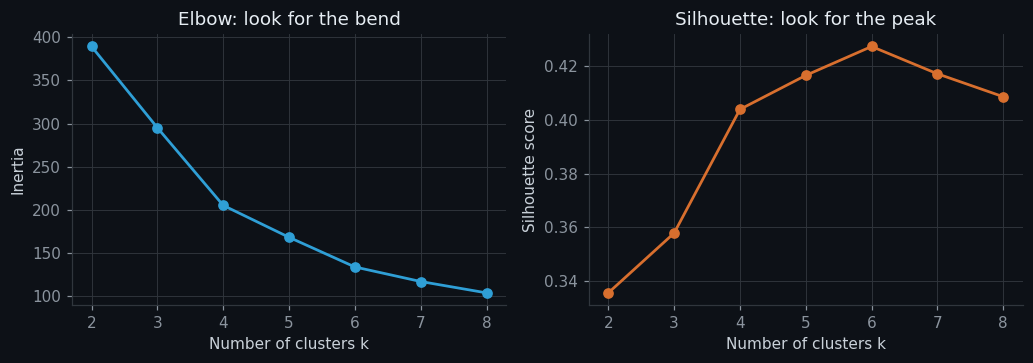

In [3]:
ks, inertias, silhouettes = [], [], []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(X)
    ks.append(k)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X, labels))
    print(f"k={k}  inertia={kmeans.inertia_:.1f}  silhouette={silhouettes[-1]:.3f}")

k_table = pd.DataFrame({"inertia": inertias, "silhouette": silhouettes}, index=pd.Index(ks, name="k"))
k_table.to_csv(RESULTS / "kmeans_k_scan.csv")
summary["k_scan"] = k_table.round(4).to_dict("index")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow: look for the bend")
axes[1].plot(ks, silhouettes, marker="o", color=ORANGE)
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette: look for the peak")
plt.tight_layout()
save_plot("kmeans_elbow_silhouette.png")

**Observations.** Inertia falls at every step, as it must: 389 at k=2, 205 at k=4, 104 at k=8. The drops shrink after k=4, from about 90 per extra cluster to 37 and then 34, so the bend sits around k=4 to 6. The silhouette peaks at k=6 (0.427), with k=5 and k=7 tied just below at 0.417. Neither score settles it alone, which matches the handout: five or six groups, with usefulness deciding. The lab locks k=5: five segments a marketing team can name and act on, at a silhouette only 0.011 below the peak.

## Part B: K-means versus DBSCAN

K-means puts every customer in a cluster. DBSCAN grows clusters from dense neighbourhoods
(radius `eps`, at least `min_samples` points) and labels everyone else as noise, `-1`.

In [4]:
kmeans = KMeans(n_clusters=5, n_init=30, random_state=42)
k_labels = kmeans.fit_predict(X)
kmeans_silhouette = silhouette_score(X, k_labels)
print("K-means silhouette:", round(kmeans_silhouette, 3))

dbscan = DBSCAN(eps=0.75, min_samples=6)
d_labels = dbscan.fit_predict(X)
is_clustered = d_labels != -1
n_clusters = len(set(d_labels[is_clustered]))
print("DBSCAN clusters:", n_clusters, " noise points:", int((~is_clustered).sum()))
if n_clusters >= 2:
    print("DBSCAN silhouette (clustered points only):",
          round(silhouette_score(X[is_clustered], d_labels[is_clustered]), 3))
summary["kmeans_k5_silhouette"] = round(float(kmeans_silhouette), 4)
summary["dbscan_eps075"] = {"clusters": int(n_clusters), "noise": int((~is_clustered).sum())}

K-means silhouette: 0.417
DBSCAN clusters: 1  noise points: 14


Describe the clusters with the means of the original features.

In [5]:
segments = customers.copy()
segments["kmeans_cluster"] = k_labels
segments["dbscan_cluster"] = d_labels
profile = segments.groupby("kmeans_cluster")[features].mean().round(1)
profile["customers"] = segments["kmeans_cluster"].value_counts().sort_index()
display(profile)
profile.to_csv(RESULTS / "kmeans_k5_profile.csv")
summary["kmeans_k5_profile"] = profile.to_dict("index")

,Age,Annual Income (k$),Spending Score (1-100),customers
kmeans_cluster,,,,
0,46.2,26.8,18.4,20
1,25.2,41.1,62.2,54
2,32.9,86.1,81.5,40
3,39.9,86.1,19.4,39
4,55.6,54.4,48.9,47


**Observations.** K-means (silhouette 0.417) gives five segments, read from the means in original units:

- **Cluster 2:** high income (86k) and high spending (81.5), 40 customers aged about 33. The obvious premium target.
- **Cluster 3:** the same income (86k) but low spending (19.4), 39 customers. They can afford more and are not spending it here.
- **Cluster 1:** the youngest group (25), modest income (41k) and above-average spending (62.2), 54 customers.
- **Cluster 4:** the oldest group (56), middle income and average spending, 47 customers.
- **Cluster 0:** older (46), low income (27k) and low spending (18.4), 20 customers.

DBSCAN at eps=0.75 finds one cluster of 186 customers plus 14 noise points, so it says nothing about segments: at this radius the dense regions all touch.

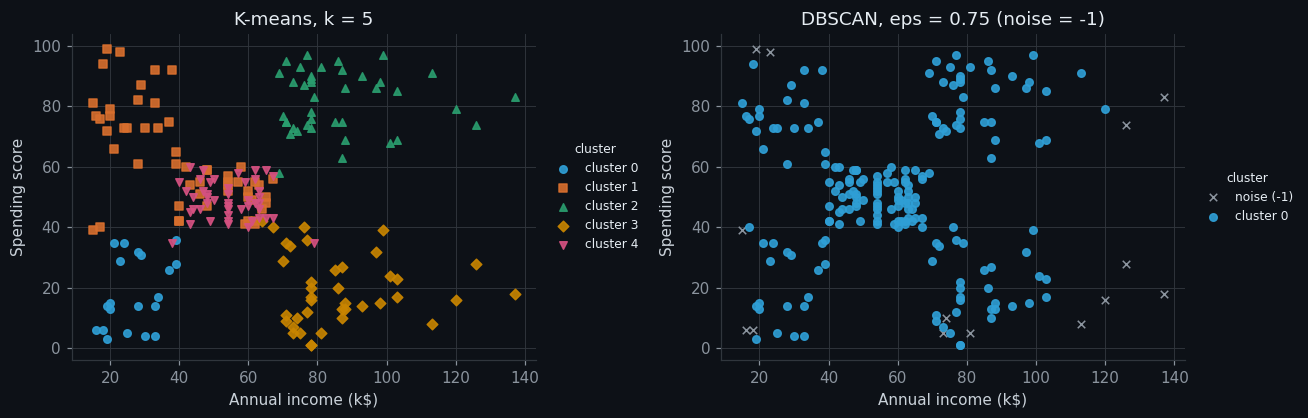

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
plot_clusters(axes[0], k_labels, "K-means, k = 5")
plot_clusters(axes[1], d_labels, "DBSCAN, eps = 0.75 (noise = -1)")
plt.tight_layout()
save_plot("kmeans_vs_dbscan.png")

**Observations.** The plots show income against spending only, so groups that differ by age overlap in the middle: K-means splits the central customers into a young group (cluster 1) and an older one (cluster 4), a split that age makes, not income. Cluster 1 also takes in the low-income, high-spending customers in the top-left corner. The two high-income groups separate cleanly into big and small spenders. DBSCAN at 0.75 paints almost everyone one colour, apart from 14 customers at the edges. The methods disagree because they define a cluster differently: K-means wants compact groups around centres and must assign everyone, while DBSCAN wants connected dense regions, and at this radius those regions chain together.

## Part C: PCA as compression, judged by a downstream model

Each digit is an 8 x 8 grid, so 64 pixel values. The official training file is used for
every choice; the official test file is touched once, for the final comparison.

training digits: 3823  test digits: 1797


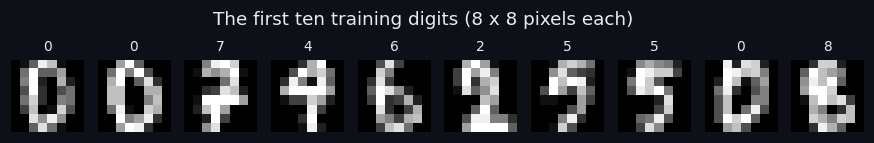

In [7]:
archive_path = DATA / "optical_recognition_handwritten_digits.zip"
columns = [f"pixel_{i}" for i in range(64)] + ["label"]
with zipfile.ZipFile(archive_path) as archive:
    members = {Path(name).name: name for name in archive.namelist()}
    train = pd.read_csv(archive.open(members["optdigits.tra"]), header=None, names=columns)
    test = pd.read_csv(archive.open(members["optdigits.tes"]), header=None, names=columns)

X_dev = train.drop(columns="label") / 16.0  # pixel values 0-16 -> 0-1
y_dev = train["label"]
X_test = test.drop(columns="label") / 16.0
y_test = test["label"]
print("training digits:", len(X_dev), " test digits:", len(X_test))

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, (_, row), label in zip(axes, X_dev.head(10).iterrows(), y_dev.head(10)):
    ax.imshow(row.to_numpy().reshape(8, 8), cmap="gray")
    ax.set_title(str(label), fontsize=9)
    ax.axis("off")
plt.suptitle("The first ten training digits (8 x 8 pixels each)", y=1.05)
save_plot("digits_first_ten.png")

Compare PCA budgets that keep 90%, 95% or 99% of the variance, judged by a classifier's
accuracy on a holdout carved from the training file.

In [8]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)

budgets = {}
baseline = LogisticRegression(max_iter=2000).fit(X_fit, y_fit)
budgets["all 64 pixels"] = {"components": 64,
                            "validation_accuracy": accuracy_score(y_valid, baseline.predict(X_valid))}
print("all 64 pixels: validation accuracy =", round(budgets["all 64 pixels"]["validation_accuracy"], 4))

for retained_variance in [0.90, 0.95, 0.99]:
    candidate = Pipeline([
        ("pca", PCA(n_components=retained_variance, svd_solver="full")),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    candidate.fit(X_fit, y_fit)
    n_kept = candidate.named_steps["pca"].n_components_
    accuracy = accuracy_score(y_valid, candidate.predict(X_valid))
    budgets[f"{retained_variance:.0%} variance"] = {"components": int(n_kept), "validation_accuracy": accuracy}
    print(f"{retained_variance:.0%} variance: {n_kept:2d} components, "
          f"validation accuracy = {accuracy:.4f}")
print("validation digits:", len(X_valid))
budget_table = pd.DataFrame(budgets).T
budget_table.to_csv(RESULTS / "pca_budgets.csv", index_label="representation")
summary["pca_budgets"] = {k: {"components": int(v["components"]),
                              "validation_accuracy": round(float(v["validation_accuracy"]), 4)}
                          for k, v in budgets.items()}

all 64 pixels: validation accuracy = 0.955
90% variance: 21 components, validation accuracy = 0.9487
95% variance: 29 components, validation accuracy = 0.9540
99% variance: 41 components, validation accuracy = 0.9561
validation digits: 956


**Observations.** On the 956 holdout digits, all 64 pixels score 0.9550. Keeping 95% of the variance needs only 29 components and scores 0.9540, one digit fewer. The 90% budget (21 components) drops to 0.9487, six digits fewer, and the 99% budget (41 components) reaches 0.9561, one digit more than the full set. So 95% keeps the accuracy with fewer than half the inputs.

Lock 95%, refit both the PCA pipeline and the full-pixel model on all training rows, then
compare them once on the official test file.

In [9]:
final_model = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("model", LogisticRegression(max_iter=2000)),
])
final_model.fit(X_dev, y_dev)
full_model = LogisticRegression(max_iter=2000).fit(X_dev, y_dev)
pca = final_model.named_steps["pca"]

full_accuracy = accuracy_score(y_test, full_model.predict(X_test))
pca_accuracy = accuracy_score(y_test, final_model.predict(X_test))
print("\nFINAL TEST (official test file)")
print("all 64 pixels accuracy:", round(full_accuracy, 4))
print("PCA components kept:", pca.n_components_,
      " variance retained:", round(pca.explained_variance_ratio_.sum(), 4))
print("PCA -> logistic accuracy:", round(pca_accuracy, 4))
print("test digits misclassified: all pixels", int(round((1 - full_accuracy) * len(y_test))),
      "/ PCA", int(round((1 - pca_accuracy) * len(y_test))))
summary["final_test"] = {"all_pixels_accuracy": round(float(full_accuracy), 4),
                         "pca_components": int(pca.n_components_),
                         "pca_variance_retained": round(float(pca.explained_variance_ratio_.sum()), 4),
                         "pca_accuracy": round(float(pca_accuracy), 4)}


FINAL TEST (official test file)
all 64 pixels accuracy: 0.9477
PCA components kept: 29  variance retained: 0.9537
PCA -> logistic accuracy: 0.9477
test digits misclassified: all pixels 94 / PCA 94


**Observations.** On the official test file both models score 0.9477: 94 of the 1,797 digits wrong for each. The PCA pipeline keeps 29 components and 95.37% of the variance, so it matches the full 64-pixel model with 45% of the inputs. This is the result Chapter 17 cites: 29 of 64 components, no loss in test accuracy.

Rebuild test digits from their component scores, and look at the cumulative explained
variance.

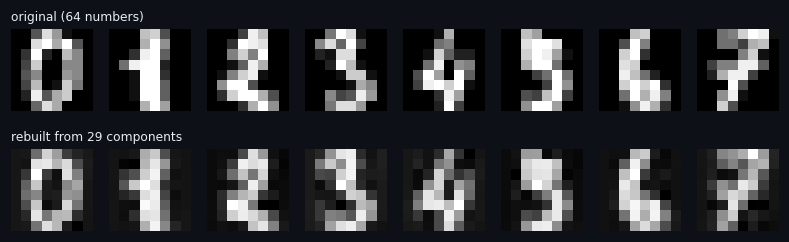

mean squared reconstruction error on all test digits (pixel scale 0-1): 0.0037


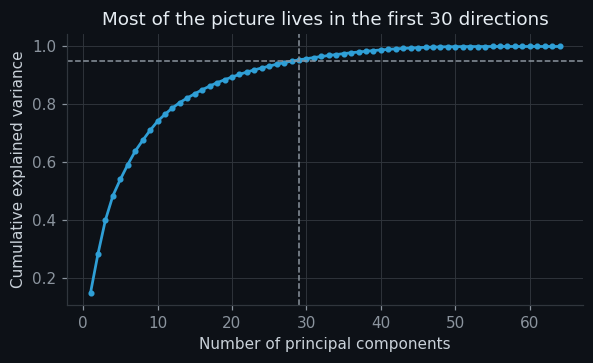

components 30 to 64 (35 of them) carry 4.63% of the variance
first component alone: 14.90%


In [10]:
reconstructed = pca.inverse_transform(pca.transform(X_test.head(8)))

fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for j in range(8):
    axes[0, j].imshow(X_test.iloc[j].to_numpy().reshape(8, 8), cmap="gray")
    axes[1, j].imshow(reconstructed[j].reshape(8, 8), cmap="gray")
    axes[0, j].axis("off")
    axes[1, j].axis("off")
axes[0, 0].set_title("original (64 numbers)", fontsize=8, loc="left")
axes[1, 0].set_title(f"rebuilt from {pca.n_components_} components", fontsize=8, loc="left")
save_plot("digits_reconstruction.png")

error = np.mean((X_test.to_numpy() - pca.inverse_transform(pca.transform(X_test))) ** 2)
print("mean squared reconstruction error on all test digits (pixel scale 0-1):", round(float(error), 4))

plt.figure(figsize=(5.5, 3.4))
all_components = PCA(svd_solver="full").fit(X_dev)
cumulative = np.cumsum(all_components.explained_variance_ratio_)
plt.plot(np.arange(1, 65), cumulative, marker=".")
plt.axhline(0.95, linestyle="--", color=MUTED, linewidth=1)
plt.axvline(pca.n_components_, linestyle="--", color=MUTED, linewidth=1)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Most of the picture lives in the first 30 directions")
plt.tight_layout()
save_plot("pca_cumulative_variance.png")
left_out = 1 - cumulative[pca.n_components_ - 1]
print(f"components {pca.n_components_ + 1} to 64 ({64 - pca.n_components_} of them) "
      f"carry {left_out:.2%} of the variance")
print(f"first component alone: {all_components.explained_variance_ratio_[0]:.2%}")
summary["reconstruction_mse"] = round(float(error), 4)
summary["variance_left_out"] = round(float(left_out), 4)

**Observations.** The rebuilt digits are blurrier, but all eight stay readable, and the average squared pixel error is 0.0037 on a 0 to 1 scale. Components 30 to 64, 35 of them, carry only 4.63% of the variance, under the handout's 5%. The first component alone holds 14.90%, so the variance is spread over many directions and no single one dominates.

Save PCA and the classifier together, so the file accepts new 64-pixel images directly.

In [11]:
model_path = MODELS / "digits_pca_logistic.joblib"
joblib.dump(final_model, model_path)

loaded = joblib.load(model_path)
first_digits = X_test.iloc[:5]
print("predicted:", loaded.predict(first_digits).tolist())
print("actual:   ", y_test.iloc[:5].tolist())
print("file size (KB):", round(model_path.stat().st_size / 1024, 1))
assert (loaded.predict(X_test) == final_model.predict(X_test)).all()
summary["saved_model_matches"] = True

predicted: [0, 1, 1, 3, 4]
actual:    [0, 1, 2, 3, 4]
file size (KB): 20.6


## Try it yourself: DBSCAN with eps=0.5

Shrink the radius from 0.75 to 0.5, count the clusters and the noise, and decide which result
serves marketing better.

DBSCAN eps=0.5 clusters: 5  noise points: 66 (33% of customers)
silhouette (clustered points only): 0.528


,Age,Annual Income (k$),Spending Score (1-100),customers
dbscan_eps05,,,,
-1,39.7,65.5,32.3,66
0,23.4,25.3,78.5,16
1,54.2,53.3,48.4,50
2,24.4,54.5,50.2,29
3,32.8,80.9,83.6,32
4,43.9,78.7,14.6,7


dbscan_eps05,-1,0,1,2,3,4
kmeans_cluster,,,,,,
0,17,0,3,0,0,0
1,9,16,1,28,0,0
2,8,0,0,0,32,0
3,30,0,1,1,0,7
4,2,0,45,0,0,0


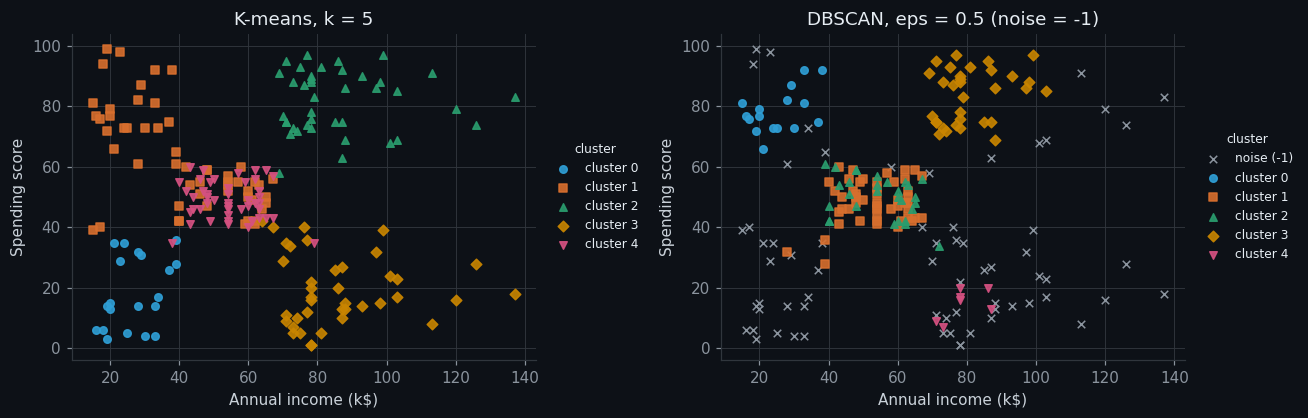

In [12]:
d_labels_05 = DBSCAN(eps=0.5, min_samples=6).fit_predict(X)
clustered_05 = d_labels_05 != -1
n_clusters_05 = len(set(d_labels_05[clustered_05]))
print("DBSCAN eps=0.5 clusters:", n_clusters_05, " noise points:", int((~clustered_05).sum()),
      f"({(~clustered_05).mean():.0%} of customers)")
if n_clusters_05 >= 2:
    print("silhouette (clustered points only):",
          round(silhouette_score(X[clustered_05], d_labels_05[clustered_05]), 3))

segments["dbscan_eps05"] = d_labels_05
profile_05 = segments.groupby("dbscan_eps05")[features].mean().round(1)
profile_05["customers"] = segments["dbscan_eps05"].value_counts().sort_index()
display(profile_05)
profile_05.to_csv(RESULTS / "dbscan_eps05_profile.csv")
# Which K-means segment does each DBSCAN group (and the noise) come from?
display(pd.crosstab(segments["kmeans_cluster"], segments["dbscan_eps05"]))
summary["dbscan_eps05"] = {"clusters": int(n_clusters_05), "noise": int((~clustered_05).sum())}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
plot_clusters(axes[0], k_labels, "K-means, k = 5")
plot_clusters(axes[1], d_labels_05, "DBSCAN, eps = 0.5 (noise = -1)")
plt.tight_layout()
save_plot("dbscan_eps05.png")

(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8");

**Observations.** At eps=0.5 DBSCAN finds five clusters and labels 66 customers (33%) as noise, as Chapter 16 describes. Its silhouette on the clustered customers is 0.528, higher than K-means' 0.417, but it earns that by leaving out the third of customers that are hardest to place, so the two numbers do not compare.

The crosstab shows who gets dropped: 30 of the 39 high-income, low-spending customers (K-means cluster 3) and 17 of the 20 older, low-income, low-spending ones (cluster 0) become noise. In return DBSCAN separates 16 young, low-income big spenders (its cluster 0) from 29 young, middle-income shoppers (its cluster 2), a split K-means does not make.

For marketing I would keep K-means with k=5. Every customer gets a segment a campaign can target, and the high-income low spenders, the group with the most room to grow, stay a full segment of 39 instead of 7. DBSCAN at 0.5 is still useful alongside it: its noise label flags customers who fit no dense group, and its split of the young shoppers is a sensible refinement inside K-means cluster 1.

## Verification checklist

- **Standardized features, elbow and silhouette both reported.** `StandardScaler` puts age, income and spending on one scale before any clustering, and Part A reports inertia and silhouette for k = 2 to 8.
- **K justified by usefulness, not one score.** The silhouette peaks at k=6 and the elbow bends around 4 to 6. k=5 wins because its five segments are distinct and nameable for marketing, at a silhouette 0.011 below the peak (Parts A and B).
- **K-means and DBSCAN compared, radius stated.** DBSCAN runs at eps=0.75 (one cluster, 14 noise) in Part B and at eps=0.5 (five clusters, 66 noise) in *Try it yourself*, both with min_samples=6, against K-means with k=5.
- **PCA fitted on training digits only, judged on the test file.** The budgets are compared on a holdout from the training file. The final PCA is fitted on the 3,823 training digits and scored once on the 1,797 official test digits (0.9477, equal to all 64 pixels).
- **The saved model reloads.** `models/digits_pca_logistic.joblib` predicts [0, 1, 1, 3, 4] for the first five test digits, which are [0, 1, 2, 3, 4], so it misreads the third digit, a 2, as a 1. The notebook also asserts that the reloaded model matches the in-memory one on all 1,797 test digits.

## Check your understanding

**1. What does PCA optimize when it chooses its first principal component?**

It picks the unit-length direction w that maximizes the variance of the centred data projected onto it, var(Xw) with ||w|| = 1. The answer is the eigenvector of the covariance matrix with the largest eigenvalue, and that eigenvalue is the variance captured. Equivalently, the first component is the line that minimizes the total squared distance from the points to their projections, which is why PCA gives the smallest squared reconstruction error for a given number of components.

**2. Why can standardization change which PCA directions appear most important?**

PCA ranks directions by variance, and variance depends on units. Unscaled, a feature measured in big numbers, such as income in dollars, has a huge variance and pulls the first component towards itself whatever its real relevance. Standardizing gives every feature variance 1, so the components reflect how features vary together instead of their units, and a different direction can come out on top. Neither choice is automatically right: standardize when the units are arbitrary, and keep raw units when their variance means something, as with the digit pixels here, which already share one 0 to 1 scale.

**3. Why should distances and apparent cluster sizes in a t-SNE or UMAP plot not be interpreted as exact properties of the original high-dimensional data?**

Both methods try to preserve local neighbourhoods, not distances. t-SNE turns distances into neighbour probabilities with a bandwidth that adapts to local density, so a dense cluster and a sparse one can come out the same size on the map, and the gaps between separated clusters are largely arbitrary. UMAP keeps somewhat more global structure but makes the same trade. The layout also shifts with the random seed and with settings like perplexity or the number of neighbours. A map shows which points are neighbours; sizes, gaps and between-cluster distances need checking in the original space.

## Chapter 15: Check your understanding

**1. Why is there no universal unsupervised-learning accuracy score?**

Accuracy needs an answer key, and unsupervised learning has none during fitting. Each method also optimizes its own objective: K-means compactness, PCA retained variance, DBSCAN density. A score that rewards one objective can penalize a structure that is just as valid under another, so the evidence has to match the task.

**2. Give one internal, one external, and one downstream form of evidence that could support an unsupervised result.**

Internal: the silhouette of the K-means segments in Part A (0.417 at k=5). External: when reference labels exist, the adjusted Rand index between the clusters and those labels, for example clustering the digits and comparing the clusters with the true digit labels. Downstream: Part C, where the 29 PCA components keep the classifier's test accuracy at 0.9477.

**3. When does an unsupervised project need a held-out split even though no label is used during fitting?**

When it claims something about new data or feeds a downstream model. Describing these 200 mall customers needs no split. PCA in Part C, though, is judged by a classifier's accuracy, so PCA has to be fitted on training digits only; fitting it on the test digits too would leak their structure into the comparison. The same applies to any preprocessing learned from data, and to checking that clusters stay stable on new customers.

## Chapter 16: Check your understanding

**1. What kind of cluster geometry does K-means favor, and why can scaling change the resulting partition?**

K-means favours compact, roughly spherical clusters of similar size: it assigns each point to the nearest centre by Euclidean distance and minimizes squared distances to the means. Scaling changes those distances. A feature with a wide range dominates the distance, so clusters form mostly along it. Here, unscaled income (standard deviation 26.3) would count almost twice as much as age (14.0); standardizing gives the three features equal weight and can change which customers end up together.

**2. What does DBSCAN do with observations that do not belong to a sufficiently dense region?**

It labels them noise, -1, and leaves them out of every cluster. A point joins a cluster only if it is a core point, with at least min_samples neighbours within eps, or lies within eps of one. In this lab that left 14 customers unassigned at eps=0.75 and 66 at eps=0.5.